# 01. Exploratory Data Analysis & Visualizations

This notebook conducts an in-depth exploratory data analysis (EDA) of the **UCI Red Wine Quality** dataset, analyzing physicochemical properties and their correlations with perceived sensory quality.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Configure plot styles
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)


## 1. Load Raw Dataset


In [2]:
data_path = Path("../data/raw/winequality-red.csv") if Path("../data/raw/winequality-red.csv").exists() else Path("data/raw/winequality-red.csv")
df_raw = pd.read_csv(data_path, sep=";")
# Clean column names
df_raw.columns = [col.strip().strip('"') for col in df_raw.columns]

print(f"Dataset Shape: {df_raw.shape}")
df_raw.head()


Dataset Shape: (1599, 12)


## 2. Dataset Structure and Data Quality Checks


In [3]:
print("Data Types and Null Value Counts:")
df_raw.info()


Data Types and Null Value Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [4]:
print(f"Missing values count:\n{df_raw.isnull().sum()}")
print(f"Duplicate rows count: {df_raw.duplicated().sum()}")


Missing values count:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64
Duplicate rows count: 240


In [5]:
df_raw.describe().T


## 3. Target Distribution: Wine Quality


 -> Saved visual: 01_quality_distribution.png


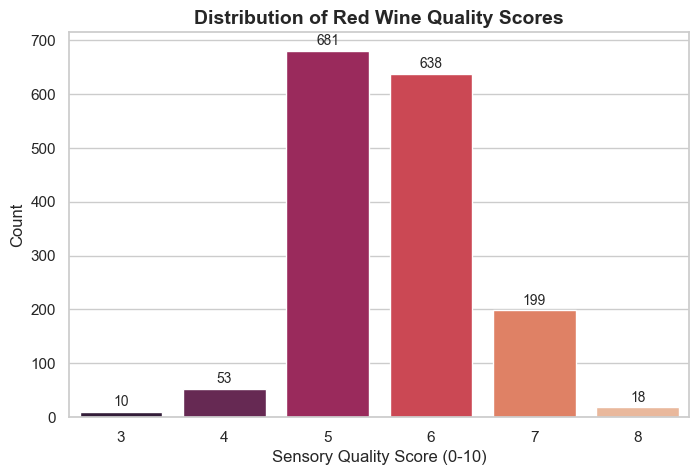

In [6]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(x="quality", data=df_raw, palette="rocket")
plt.title("Distribution of Red Wine Quality Scores", fontsize=14, fontweight="bold")
plt.xlabel("Sensory Quality Score (0-10)")
plt.ylabel("Count")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha="center", va="baseline", fontsize=10, xytext=(0, 4), textcoords="offset points")
plt.show()


## 4. Correlation Analysis


 -> Saved visual: 02_correlation_matrix.png


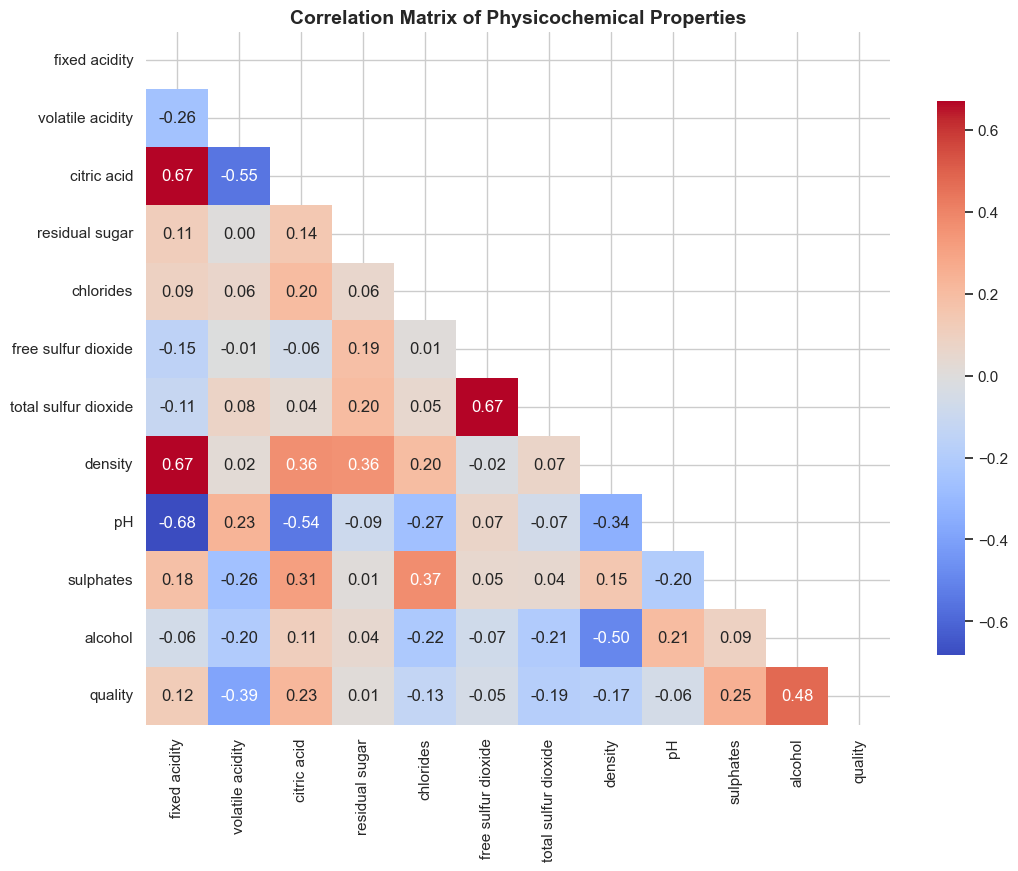

In [7]:
plt.figure(figsize=(12, 9))
corr = df_raw.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", cbar_kws={"shrink": .8})
plt.title("Correlation Matrix of Physicochemical Properties", fontsize=14, fontweight="bold")
plt.show()


In [8]:
corr_quality = df_raw.corr()["quality"].sort_values(ascending=False)
print("Correlation with Wine Quality:\n", corr_quality)


Correlation with Wine Quality:
 quality                 1.000000
alcohol                 0.476166
sulphates               0.251397
citric acid             0.226373
fixed acidity           0.124052
residual sugar          0.013732
free sulfur dioxide    -0.050656
pH                     -0.057731
chlorides              -0.128907
density                -0.174919
total sulfur dioxide   -0.185100
volatile acidity       -0.390558
Name: quality, dtype: float64


## 5. Key Physicochemical Influences on Quality


 -> Saved visual: 03_physicochemical_boxplots.png


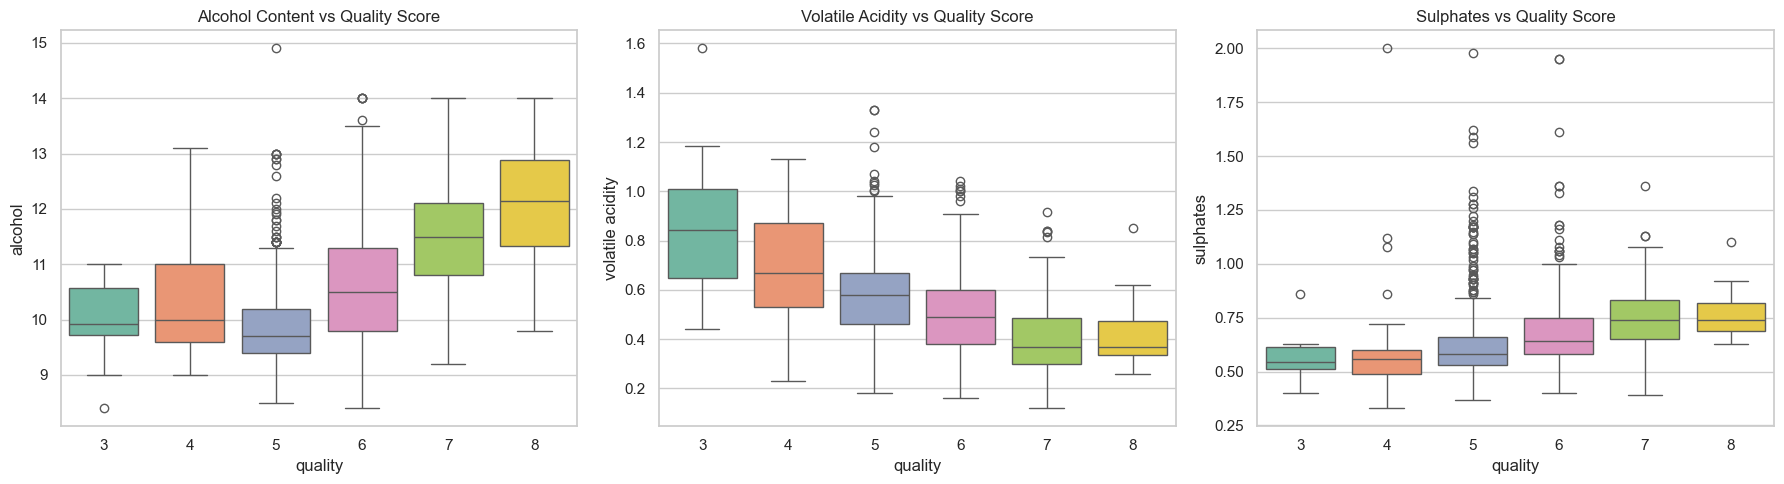

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(ax=axes[0], x="quality", y="alcohol", data=df_raw, palette="Set2")
axes[0].set_title("Alcohol Content vs Quality Score")

sns.boxplot(ax=axes[1], x="quality", y="volatile acidity", data=df_raw, palette="Set2")
axes[1].set_title("Volatile Acidity vs Quality Score")

sns.boxplot(ax=axes[2], x="quality", y="sulphates", data=df_raw, palette="Set2")
axes[2].set_title("Sulphates vs Quality Score")

plt.tight_layout()
plt.show()


## 6. Summary of Key Findings
- **Alcohol**: Highest positive correlation (~0.48) with quality score. Better wines consistently feature higher alcohol content.
- **Volatile Acidity**: Strongest negative correlation (~ -0.39). Acetic acid imparts vinegar odor and sour notes.
- **Sulphates**: Positive correlation (~0.25). Acts as antioxidant and antimicrobial preservative.
- **Duplicates**: 240 duplicates identified requiring deduplication prior to modeling.
